<a href="https://colab.research.google.com/github/jonathan-ha1/Problem-Set-4/blob/main/Copy_of_ps4_starter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 3916 PS4 — The Model That Fit Too Well

**ECON 3916 · Applied Data Analytics** · Topics 12-15 · 100 points · your role: Analyst, Revenue Forecasting

This is the **starter**: the structure of the set in rubric order. Fill the empty cells; keep every heading so the grader finds each step. The brief on Canvas has the full text of every step, the numbers you must hit and the rubric. Every claim goes in a text cell: the reader is analyst's audience, not a grader with a kernel.

**AI is not allowed in Phases 1–3.** Generative AI is **prohibited** in Phases 1 through 3. You fit the regressions, run the diagnostics and build the validation split yourself. AI is authorised and required in Phase 4.

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)     # one generator, so every draw reruns the same way
pd.set_option('display.precision', 3)

## Phase 1: Reproduce the 0.94 (30 pts)

### Step 1.1: Build the store panel (10 pts)

In [2]:
import statsmodels.api as sm

# What the brief fixes (Step 1.1). Keep it here so the grader can rerun you.
N_STORES = 400               # at least 400 stores
# predictors: floor area, foot traffic, local median income, years open,
# several that are irrelevant, and one that is nearly a linear combination of two others

In [3]:
rng = np.random.default_rng(42)
n = 400
stores = pd.DataFrame({"floor_area": rng.uniform(2000, 40000, n),
                       "foot_traffic": rng.normal(15000, 4000, n),
                       "median_income": rng.normal(70000, 15000, n),
                       "years_open": rng.uniform(1, 30, n)})
stores["size_index"] = stores["floor_area"] / 1000 + stores["foot_traffic"] / 1000 + rng.normal(0, 0.5, n)
for j in range(60):
    stores[f"junk_{j}"] = rng.normal(size=n)
revenue = (20000 + 30 * stores["floor_area"] - 0.0004 * stores["floor_area"] ** 2 + 8 * stores["foot_traffic"]
           + 1.5 * stores["median_income"] + 2000 * stores["years_open"] + rng.normal(0, stores["floor_area"]))
print(stores.shape)
print(revenue.describe().round(0))

(400, 65)
count    4.000e+02
mean     6.813e+05
std      1.620e+05
min      2.827e+05
25%      5.526e+05
50%      7.246e+05
75%      8.110e+05
max      1.019e+06
dtype: float64


*The data-generating process, recorded: every predictor and the true revenue equation.*

The panel has 400 simulated stores whose revenue depends on floor area, foot traffic, local median income, and years open, with revenue growing more slowly for the biggest stores and varying more as stores get larger. It also includes size_index, which is almost exactly floor area plus foot traffic, and 60 junk columns of pure random noise. Neither size_index nor the junk columns have any effect on revenue, and the exact formula is in the code above.

### Step 1.2: Fit it the way they did (12 pts)

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

full_fit = sm.OLS(revenue, sm.add_constant(stores)).fit()
print(f"R-squared, every predictor, all {n} stores: {full_fit.rsquared:.3f}")

X_tr, X_te, y_tr, y_te = train_test_split(sm.add_constant(stores), revenue, test_size=0.3, random_state=0)
split_fit = sm.OLS(y_tr, X_tr).fit()
r2_in = split_fit.rsquared
r2_out = r2_score(y_te, split_fit.predict(X_te))
print(f"R-squared on the {len(y_tr)} training stores: {r2_in:.3f}")
print(f"R-squared on the {len(y_te)} held-out stores: {r2_out:.3f}")
print(f"gap: {r2_in - r2_out:.3f}")

R-squared, every predictor, all 400 stores: 0.930
R-squared on the 280 training stores: 0.935
R-squared on the 120 held-out stores: 0.897
gap: 0.038


Fitting OLS with every predictor on all 400 stores gives an R-squared of 0.930, which is close to the 0.94 in the handover note. When the model is fitted on 280 stores and scored on the 120 stores it never saw, R-squared drops from 0.935 to 0.897, a gap of 0.038. This shows the handover number came from the same stores the model was fitted to, so it was higher than what the model gets on new stores.

### Step 1.3: Say what R-squared is (8 pts)

In [5]:
noisy = stores.copy()
for j in range(3):
    noisy[f"noise_{j}"] = rng.normal(size=n)
more = sm.OLS(revenue, sm.add_constant(noisy)).fit()
print(f"{'':>20}{'R-squared':>11}{'adjusted':>11}")
print(f"{'every predictor':>20}{full_fit.rsquared:>11.4f}{full_fit.rsquared_adj:>11.4f}")
print(f"{'+ 3 noise columns':>20}{more.rsquared:>11.4f}{more.rsquared_adj:>11.4f}")

                      R-squared   adjusted
     every predictor     0.9297     0.9160
   + 3 noise columns     0.9299     0.9155


In-sample R-squared can’t go down when a predictor is added, so a model with more columns will always look at least as good, even when those columns are useless. Adding three columns of pure noise shows this, since R-squared rose from 0.9297 to 0.9299 while adjusted R-squared fell from 0.9160 to 0.9155. This means in-sample R-squared can’t be used to choose between models, so they should be compared on stores they weren’t fitted to instead.

## Phase 2: Diagnose the Failure (35 pts)

### Step 2.1: Look at the residuals (20 pts)

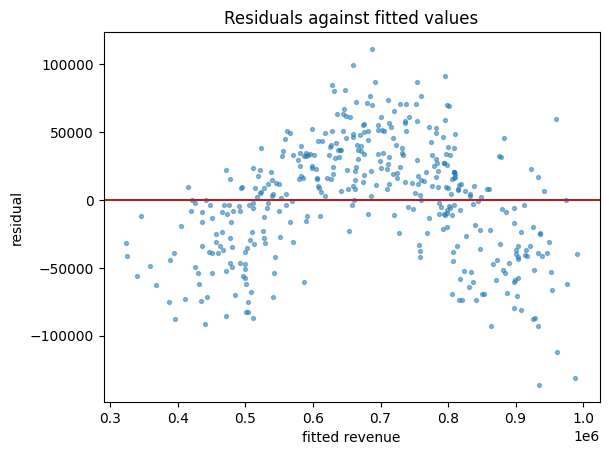

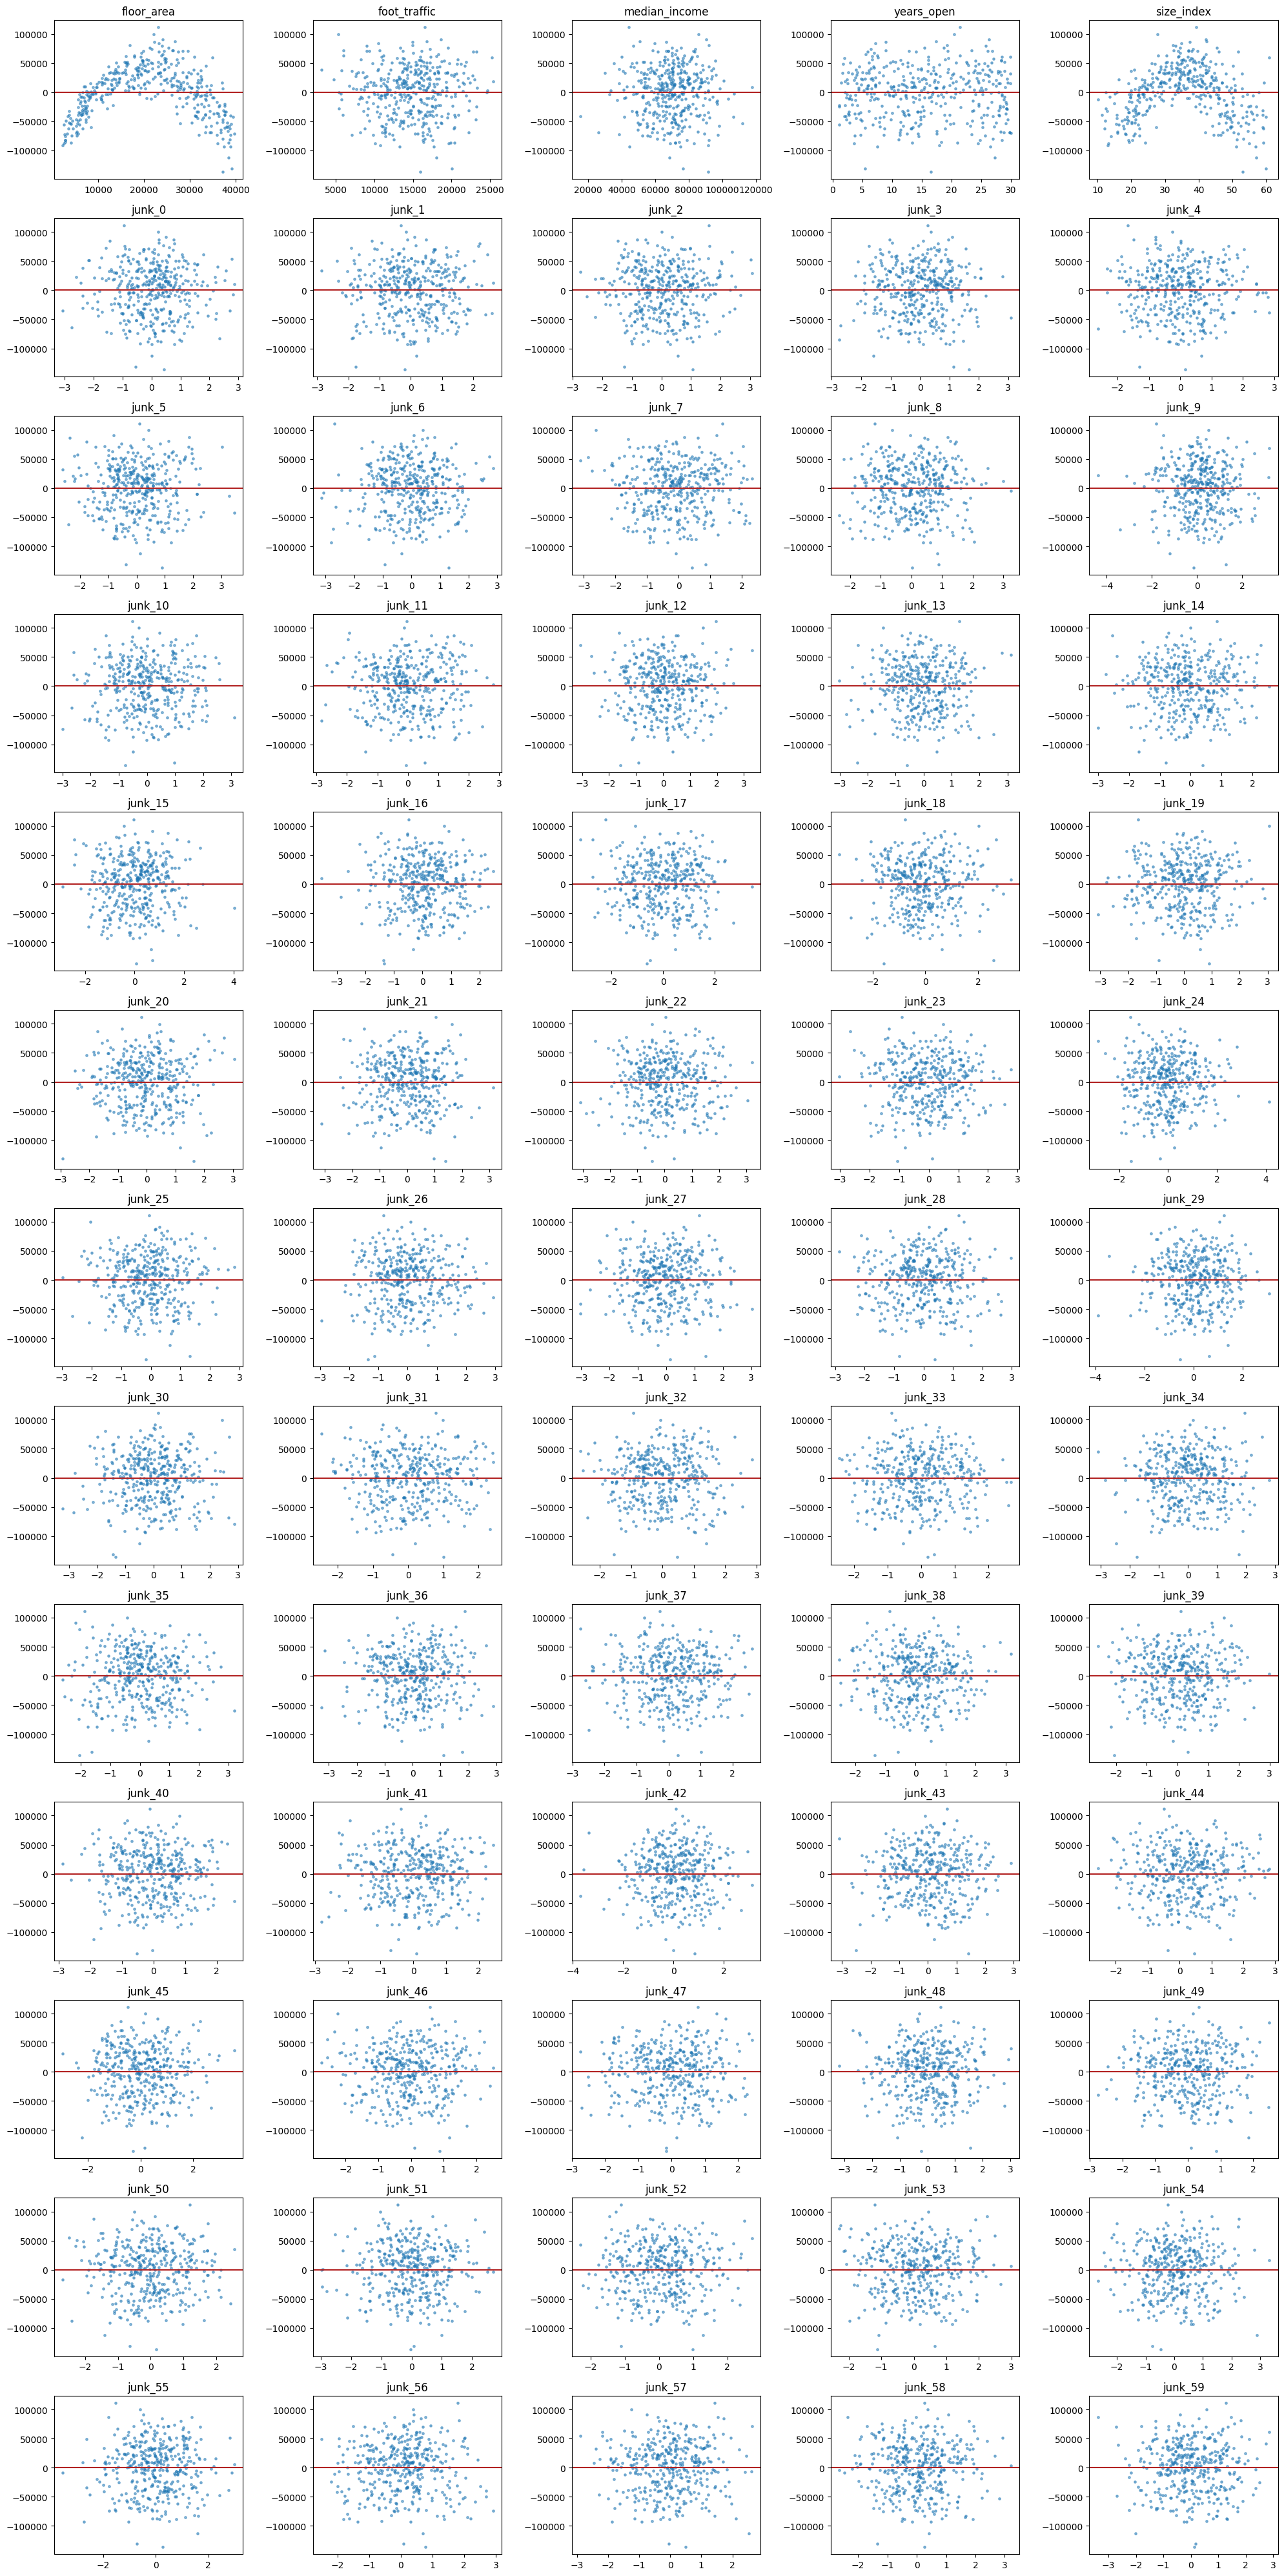

floor_area
smallest    29315.0
2           20529.0
3           32494.0
largest     38746.0
dtype: float64
floor_area slope 13.822 both ways | classical SE 5.137 | HC3 SE 5.678


In [6]:
resid = full_fit.resid
robust_fit = sm.OLS(revenue, sm.add_constant(stores)).fit(cov_type="HC3")

plt.scatter(full_fit.fittedvalues, resid, s=8, alpha=0.5)
plt.axhline(0, color="firebrick")
plt.xlabel("fitted revenue"); plt.ylabel("residual"); plt.title("Residuals against fitted values")
plt.show()

fig, axes = plt.subplots(13, 5, figsize=(20, 40))
for ax, col in zip(axes.flatten(), stores.columns):
    ax.scatter(stores[col], resid, s=6, alpha=0.5)
    ax.axhline(0, color="firebrick")
    ax.set_title(col)
plt.tight_layout()
plt.show()

print(resid.groupby(pd.qcut(stores["floor_area"], 4, labels=["smallest", "2", "3", "largest"]), observed=True).std().round(0))
print(f"floor_area slope {full_fit.params['floor_area']:.3f} both ways | classical SE {full_fit.bse['floor_area']:.3f} | HC3 SE {robust_fit.bse['floor_area']:.3f}")

The residuals spread out more for bigger stores, with a standard deviation of about 20,529 in the second quarter of floor area versus 38,746 in the largest, which breaks the constant-variance assumption, and while this leaves the floor_area estimate at 13.822 under both fits, it makes the classical standard error wrong, so the HC3 standard error comes out at 5.678 instead of 5.137. The residuals against floor area also form an arch that is negative for the smallest and largest stores and positive in the middle, which breaks the assumption that revenue is linear in the predictors, since the model missed that revenue grows more slowly for bigger stores. Unlike the spread problem, this curve makes the floor_area estimate itself misleading, because one straight-line slope can’t describe a bend, and it throws off the standard error too because the missed curve gets counted as noise.

### Step 2.2: The over-forecast on big stores (15 pts)

In [7]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

size_group = pd.qcut(stores["floor_area"], 5, labels=["smallest", "2", "3", "4", "largest"])
by_size = resid.groupby(size_group, observed=True).mean()
pct = by_size / revenue.groupby(size_group, observed=True).mean() * 100
print(pd.DataFrame({"mean residual": by_size.round(0), "% of revenue": pct.round(1)}))

Xi = sm.add_constant(stores)
vifs = pd.Series({c: variance_inflation_factor(Xi.to_numpy(), i) for i, c in enumerate(Xi.columns) if c != "const"})
main = ["floor_area", "foot_traffic", "median_income", "years_open", "size_index"]
print(vifs[main].round(1))
print(f"largest junk VIF: {vifs.drop(main).max():.2f}")

fit_drop = sm.OLS(revenue, sm.add_constant(stores.drop(columns="size_index"))).fit()
print(f"R-squared {full_fit.rsquared:.6f} with size_index, {fit_drop.rsquared:.6f} without, change {full_fit.rsquared - fit_drop.rsquared:.6f}")
print(f"SE of floor_area {full_fit.bse['floor_area']:.3f} with size_index, {fit_drop.bse['floor_area']:.3f} without, {full_fit.bse['floor_area'] / fit_drop.bse['floor_area']:.1f} times larger")

            mean residual  % of revenue
floor_area                             
smallest         -37821.0          -8.8
2                 18985.0           3.2
3                 40253.0           5.5
4                 15011.0           1.9
largest          -36427.0          -4.3
floor_area       560.2
foot_traffic      81.1
median_income      1.2
years_open         1.2
size_index       671.4
dtype: float64
largest junk VIF: 1.29
R-squared 0.929670 with size_index, 0.929670 without, change 0.000000
SE of floor_area 5.137 with size_index, 0.240 without, 21.4 times larger


The model over-forecasts the largest fifth of stores by an average of $36,427, or about 4.3% of their revenue, so the error depends on store size. size_index has a VIF of 671.4, and floor_area and foot_traffic are also high at 560.2 and 81.1, because size_index is almost the same as those two added together. A high VIF makes the floor_area standard error about 21 times larger, but it doesn’t hurt the predictions, since dropping size_index changes R-squared by 0.000000, so removing it wouldn’t fix the over-forecast.

## Phase 3: Build Something Honest (25 pts)

### Step 3.1: The complexity sweep (14 pts)

1: floor area only              1 columns | training RMSE    61,216 | held-out RMSE    66,625
2: + traffic, income, years     4 columns | training RMSE    45,052 | held-out RMSE    48,748
3: + floor area squared         5 columns | training RMSE    22,734 | held-out RMSE    24,741
4: + size_index                 6 columns | training RMSE    22,734 | held-out RMSE    24,739
5: + 20 junk                   26 columns | training RMSE    21,853 | held-out RMSE    26,471
6: + all 60 junk               66 columns | training RMSE    20,174 | held-out RMSE    27,774
7: + 30 junk squared           96 columns | training RMSE    19,444 | held-out RMSE    29,496
8: + all 60 junk squared      126 columns | training RMSE    17,115 | held-out RMSE    33,944


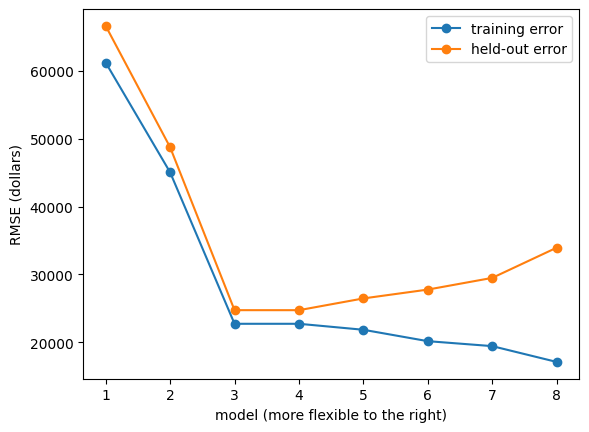

held-out error is lowest at model 4


In [8]:
big = stores.copy()
big["floor_area_sq"] = stores["floor_area"] ** 2
for j in range(60):
    big[f"junk_{j}_sq"] = stores[f"junk_{j}"] ** 2

main = ["floor_area", "foot_traffic", "median_income", "years_open"]
junk = [f"junk_{j}" for j in range(60)]
junk_sq = [f"junk_{j}_sq" for j in range(60)]
models = {"1: floor area only": ["floor_area"],
          "2: + traffic, income, years": main,
          "3: + floor area squared": main + ["floor_area_sq"],
          "4: + size_index": main + ["floor_area_sq", "size_index"],
          "5: + 20 junk": main + ["floor_area_sq", "size_index"] + junk[:20],
          "6: + all 60 junk": main + ["floor_area_sq", "size_index"] + junk,
          "7: + 30 junk squared": main + ["floor_area_sq", "size_index"] + junk + junk_sq[:30],
          "8: + all 60 junk squared": main + ["floor_area_sq", "size_index"] + junk + junk_sq}

B_tr, B_te, r_tr, r_te = train_test_split(big, revenue, test_size=0.3, random_state=0)
train_rmse, test_rmse = [], []
for name, cols in models.items():
    fit = sm.OLS(r_tr, sm.add_constant(B_tr[cols])).fit()
    train_rmse.append(np.sqrt(np.mean((fit.fittedvalues - r_tr) ** 2)))
    test_rmse.append(np.sqrt(np.mean((fit.predict(sm.add_constant(B_te[cols])) - r_te) ** 2)))
    print(f"{name:<28}{len(cols):>5} columns | training RMSE {train_rmse[-1]:>9,.0f} | held-out RMSE {test_rmse[-1]:>9,.0f}")

plt.plot(range(1, 9), train_rmse, marker="o", label="training error")
plt.plot(range(1, 9), test_rmse, marker="o", label="held-out error")
plt.xlabel("model (more flexible to the right)"); plt.ylabel("RMSE (dollars)"); plt.legend()
plt.show()
print(f"held-out error is lowest at model {int(np.argmin(test_rmse)) + 1}")

Training error keeps falling as the models get more flexible, from 61,216 dollars to 17,115 dollars, but held-out error only falls until model 4 at 24,739 dollars, which is almost tied with model 3 at 24,741 dollars, and then climbs to 33,944 dollars. Left of that point the models are too simple to match how revenue really works, which is bias, and adding floor area squared in model 3 fixes most of it. Right of that point the junk columns make the model fit noise in the training stores, which is variance, so it does worse on new stores.

### Step 3.2: Choose, and be honest about the estimate (11 pts)

In [9]:
from sklearn.model_selection import KFold

def fold_errors(X, y, cols, folds):
    errs = []
    for a, b in folds.split(X):
        fit = sm.OLS(y.iloc[a], sm.add_constant(X.iloc[a][cols])).fit()
        errs.append(np.mean((fit.predict(sm.add_constant(X.iloc[b][cols])) - y.iloc[b]) ** 2))
    return np.array(errs)

names = list(models.keys())
col_sets = list(models.values())

kf = KFold(n_splits=5, shuffle=True, random_state=0)
cv_mse = [fold_errors(big, revenue, c, kf).mean() for c in col_sets]
best = int(np.argmin(cv_mse))
e = fold_errors(big, revenue, col_sets[best], kf)
low = e.mean() - 2 * e.std(ddof=1) / np.sqrt(5)
high = e.mean() + 2 * e.std(ddof=1) / np.sqrt(5)
print(f"CV picks model {names[best]}: RMSE {np.sqrt(e.mean()):,.0f}, rough interval {np.sqrt(low):,.0f} to {np.sqrt(high):,.0f}")

outer = KFold(n_splits=5, shuffle=True, random_state=0)
outer_scores, chosen = [], []
for a, b in outer.split(big):
    inner = KFold(n_splits=5, shuffle=True, random_state=1)
    X_in, y_in = big.iloc[a], revenue.iloc[a]
    d = int(np.argmin([fold_errors(X_in, y_in, c, inner).mean() for c in col_sets]))
    chosen.append(d + 1)
    fit = sm.OLS(y_in, sm.add_constant(X_in[col_sets[d]])).fit()
    outer_scores.append(np.mean((fit.predict(sm.add_constant(big.iloc[b][col_sets[d]])) - revenue.iloc[b]) ** 2))
print(f"nested estimate: RMSE {np.sqrt(np.mean(outer_scores)):,.0f}, against the best CV score {np.sqrt(min(cv_mse)):,.0f}")
print(f"model chosen in each outer fold: {chosen}")

CV picks model 3: + floor area squared: RMSE 23,587, rough interval 22,075 to 25,007
nested estimate: RMSE 23,606, against the best CV score 23,587
model chosen in each outer fold: [3, 4, 3, 3, 3]


Using cross-validation, model 3 comes out on top, which is the four real predictors plus floor area squared, and its expected error is about 23,587 dollars, somewhere between 22,075 and 25,007 dollars. The catch is that this number is a little too good, since we used the same data to pick model 3 and then to grade it. Nested cross-validation gets around this by keeping the stores used to pick the model separate from the ones used to grade it, and it gives a more honest estimate of 23,606 dollars.

## Phase 4: AI Expansion — The Co-Pilot Era (10 pts)

**Status: AI usage AUTHORISED and REQUIRED.** Use the **P.R.I.M.E. framework**.

### Task 4.1: The learning curve (4 pts)

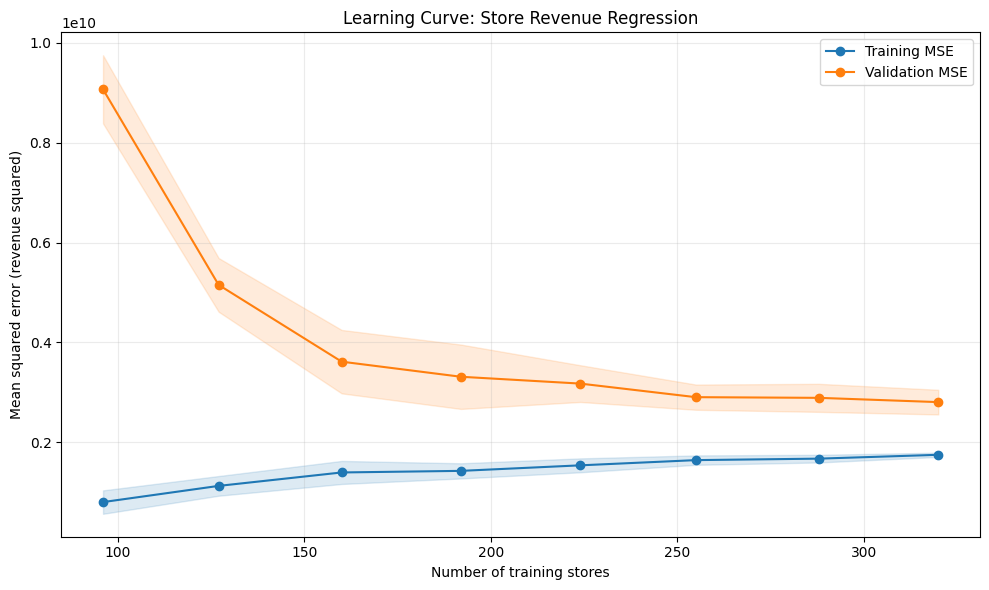

Final training MSE:   1,748,375,926.39
Final validation MSE: 2,803,942,157.64
Train-validation gap: 1,055,566,231.25
Relative gap:         60.4%
Final training RMSE:   41,814
Final validation RMSE: 52,952
Recent validation MSE change: -98,843,151.48
Diagnosis: Possible high variance.
More representative stores may help.
Model 3 final training RMSE:   22,951
Model 3 final validation RMSE: 23,186


In [10]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import KFold, learning_curve
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

X = stores
y = revenue

X = np.asarray(X)
y = np.asarray(y).ravel()

# StandardScaler is fitted separately within each training fold,
# preventing information leakage from validation observations.
model = make_pipeline(
    StandardScaler(),
    LinearRegression()
)

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_sizes, train_scores, val_scores = learning_curve(
    estimator=model,
    X=X,
    y=y,
    train_sizes=np.linspace(0.3, 1.0, 8),
    cv=cv,
    scoring="neg_mean_squared_error",
    shuffle=True,
    random_state=42,
    n_jobs=-1
)

# sklearn returns negative MSE because higher scores are preferred.
train_mse = -train_scores
val_mse = -val_scores

train_mean = train_mse.mean(axis=1)
val_mean = val_mse.mean(axis=1)

train_std = train_mse.std(axis=1)
val_std = val_mse.std(axis=1)

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    train_sizes, train_mean,
    marker="o", label="Training MSE", color="tab:blue"
)
ax.plot(
    train_sizes, val_mean,
    marker="o", label="Validation MSE", color="tab:orange"
)

# Shaded bands represent +/- 1 standard deviation across CV folds.
ax.fill_between(
    train_sizes,
    np.maximum(0, train_mean - train_std),
    train_mean + train_std,
    color="tab:blue", alpha=0.15
)
ax.fill_between(
    train_sizes,
    np.maximum(0, val_mean - val_std),
    val_mean + val_std,
    color="tab:orange", alpha=0.15
)

ax.set_xlabel("Number of training stores")
ax.set_ylabel("Mean squared error (revenue squared)")
ax.set_title("Learning Curve: Store Revenue Regression")
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

# MECHANISM CHECK:
# GAP: Large validation MSE relative to training MSE suggests
# high variance / overfitting. More representative stores may
# reduce the gap, especially if validation error is still falling.
#
# LEVEL: If both curves converge at similarly high MSE,
# the model may have high bias / underfitting. Better features,
# nonlinear relationships, or a different model may help more.
#
# A small gap alone does not prove high bias: both errors could
# be low. "High" requires a business-defined acceptable error.
#
# If validation MSE has already plateaued, additional stores
# may offer limited benefit even when a gap remains.

gap = val_mean[-1] - train_mean[-1]
relative_gap = gap / max(train_mean[-1], 1e-12)

print(f"Final training MSE:   {train_mean[-1]:,.2f}")
print(f"Final validation MSE: {val_mean[-1]:,.2f}")
print(f"Train-validation gap: {gap:,.2f}")
print(f"Relative gap:         {relative_gap:.1%}")
print(f"Final training RMSE:   {np.sqrt(train_mean[-1]):,.0f}")
print(f"Final validation RMSE: {np.sqrt(val_mean[-1]):,.0f}")

# Compare the last three validation points for a rough trend.
recent_change = val_mean[-1] - val_mean[-3]
print(f"Recent validation MSE change: {recent_change:,.2f}")

if relative_gap > 0.25 and recent_change < 0:
    print("Diagnosis: Possible high variance.")
    print("More representative stores may help.")
elif relative_gap <= 0.25:
    print("Diagnosis: Small generalization gap.")
    print("Compare validation error with business tolerance.")
    print("If error is too high, prioritize features/modeling.")
else:
    print("Diagnosis: Large gap without clear recent improvement.")
    print("Investigate overfitting and data quality before")
    print("investing heavily in additional store observations.")

X3 = np.asarray(big[models["3: + floor area squared"]])
train_sizes3, train_scores3, val_scores3 = learning_curve(
    estimator=model,
    X=X3,
    y=y,
    train_sizes=np.linspace(0.3, 1.0, 8),
    cv=cv,
    scoring="neg_mean_squared_error",
    shuffle=True,
    random_state=42,
    n_jobs=-1
)
print(f"Model 3 final training RMSE:   {np.sqrt(-train_scores3.mean(axis=1)[-1]):,.0f}")
print(f"Model 3 final validation RMSE: {np.sqrt(-val_scores3.mean(axis=1)[-1]):,.0f}")

On the full 65-column model, the learning curve ends with a training error of 41,814 dollars and a validation error of 52,952 dollars, and because that gap is large and still shrinking, the AI’s code says more stores may help. That disagrees with Phase 3, and Phase 3 is right, because even the training error is far above the 22,951 dollars that model 3 reaches with floor area squared, so more stores could only pull the validation error down toward a level that is still too high. When the same curve is run on model 3, the gap almost disappears at 22,951 versus 23,186 dollars and the curve is flat, so better features are the higher-return investment, not more stores.

### Task 4.2: What "validated" meant (3 pts)

> **No AI on this task, and no transcript.** Here you are the reviewer.

The departing analyst's cell, copied from the brief. For (b), run it as it is with 300 pure-noise columns alone as `X` and your Phase 1 revenue as `y`.

In [11]:
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LinearRegression

noise_rng = np.random.default_rng(99)
X = noise_rng.normal(size=(400, 300))
y = revenue

X_scaled = StandardScaler().fit_transform(X)
X_sel = SelectKBest(f_regression, k=20).fit_transform(X_scaled, y)
scores = cross_val_score(LinearRegression(), X_sel, y, cv=5, scoring="r2")
print(f"Validated R^2: {scores.mean():.2f}")

Validated R^2: 0.10


In [12]:
from sklearn.pipeline import Pipeline

pipe = Pipeline([("scale", StandardScaler()),
                 ("select", SelectKBest(f_regression, k=20)),
                 ("ols", LinearRegression())])
pipe_scores = cross_val_score(pipe, X, y, cv=5, scoring="r2")
print(f"Pipeline R^2: {pipe_scores.mean():.2f}")
print(f"gap: {scores.mean() - pipe_scores.mean():.2f}")

Pipeline R^2: -0.15
gap: 0.25


(a) The step that inflates the score is SelectKBest, because it picks the 20 columns most related to revenue using all 400 stores, so the stores in each test fold have already helped choose the columns. The StandardScaler is harmless for OLS with an intercept, because rescaling a column only changes the size of its coefficient and the intercept absorbs any shift, so the predictions and R-squared stay the same.

(b) On 300 columns of pure noise, the analyst’s cell prints a validated R-squared of 0.10, which makes it look like the noise can predict revenue a little. When the same three steps run inside a Pipeline so they are refitted in each fold, R-squared drops to −0.15, a gap of 0.25, which means the noise actually predicts worse than just guessing the average.

(c) It’s a special case of the Step 3.2 problem, because in both cases the same data was used to make a choice and then to score it, except here the choice is which columns to keep instead of which model to use.

### Task 4.3: The handover note (3 pts)

This model predicts each store’s monthly revenue from its floor area, floor area squared, foot traffic, local median income, and years open. The old version used 65 columns, including a near-duplicate of floor area plus foot traffic and 60 columns of pure noise, and it left out floor area squared, which is why it over-forecast the biggest stores by about 4.3% of their revenue while still showing an R-squared of 0.93 on the stores it was fitted to.

The honest expected error is about 23,606 dollars per store per month, which comes from nested cross-validation, so it covers both choosing the model and fitting it. That is the number to expect next month, not the old 0.94, which was measured on the same stores the model learned from.

The model will fail in two situations. The first is the largest stores, because revenue varies more as stores get bigger, so their forecasts will miss by more than the average error suggests. The second is any store bigger than the 2,000 to 40,000 square feet the model was built on, because the floor area squared term bends the forecast, and outside that range nothing checks whether the bend is still right.

Next, I would build error ranges that widen with store size so the biggest stores get honest warnings, and I would put effort into better features rather than more stores, since the learning curve showed that more stores barely help once floor area squared is in the model.

### AI Transcript

Paste **your prompt exactly as you sent it** and the model's replies **exactly as they came back**, then one line on each change you made. Name the model and the date.

*Model and date:* ChatGPT GPT-6, 11/18/2026

*Prompt:*

[Prep] Act as a machine learning engineer who diagnoses model performance problems in production.

[Request] I have a store-level revenue regression with 400 rows and about 12 predictors. Write Python that produces a learning curve -- training and validation error as a function of training set size -- and interprets it to distinguish a high-bias problem from a high-variance one.

[Iterate] scikit-learn, numpy and matplotlib. Reuse my X and y. Plot both curves on one axis with a shaded band for variability across folds.

[Mechanism Check] Add comments explaining what the GAP between the two curves indicates versus what the LEVEL both converge to indicates, and what each implies about whether collecting more data would help.

[Evaluate] Run it on my data and tell me whether more stores or better features is the higher-return investment.

*Reply:*

**Learning curve: Store-level revenue regression**

With 400 stores and approximately 12 predictors, a learning curve can help determine whether your model would benefit more from collecting additional store observations or improving its features and modeling approach.

We'll use:

- 5-fold cross-validation to estimate performance on unseen stores.
- Mean squared error (MSE) for training and validation error.
- Numerical results showing variability across folds.
- Training sizes from 40 to 320 stores, since each cross-validation training fold contains 80% of the 400 observations.
- Ridge regression as a baseline, with standardized predictors.

The key distinction is that a large training–validation gap suggests high variance, while both errors converging at an unacceptably high level suggests high bias.

**1. Python implementation**

The code below uses your existing `X` and `y`, displays both sets of errors numerically, and prints a preliminary diagnosis.

```python
import numpy as np

from sklearn.model_selection import KFold, learning_curve
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

# X: store-level predictors, shape approximately (400, 12)
# y: revenue outcome, shape (400,)

X = np.asarray(X)
y = np.asarray(y).ravel()

# StandardScaler is fitted separately within each training fold,
# preventing information leakage from validation observations.
model = make_pipeline(
    StandardScaler(),
    Ridge(alpha=1.0)
)

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_sizes, train_scores, val_scores = learning_curve(
    estimator=model,
    X=X,
    y=y,
    train_sizes=np.linspace(0.125, 1.0, 10),
    cv=cv,
    scoring="neg_mean_squared_error",
    shuffle=True,
    random_state=42,
    n_jobs=-1
)

# sklearn returns negative MSE because higher scores are preferred.
train_mse = -train_scores
val_mse = -val_scores

train_mean = train_mse.mean(axis=1)
val_mean = val_mse.mean(axis=1)

train_std = train_mse.std(axis=1)
val_std = val_mse.std(axis=1)

# Display the learning curve numerically.
# Standard deviations represent variability across CV folds.
print("\nLearning Curve Results")
print("-" * 82)
print(
    f"{'Stores':>8} | {'Training MSE':>16} | "
    f"{'Validation MSE':>16} | {'Train Std':>12} | "
    f"{'Val Std':>12}"
)
print("-" * 82)

for i, size in enumerate(train_sizes):
    print(
        f"{size:>8} | "
        f"{train_mean[i]:>16,.2f} | "
        f"{val_mean[i]:>16,.2f} | "
        f"{train_std[i]:>12,.2f} | "
        f"{val_std[i]:>12,.2f}"
    )

# MECHANISM CHECK:
# GAP: Large validation MSE relative to training MSE suggests
# high variance / overfitting. More representative stores may
# reduce the gap, especially if validation error is still falling.
#
# LEVEL: If both curves converge at similarly high MSE,
# the model may have high bias / underfitting. Better features,
# nonlinear relationships, or a different model may help more.
#
# A small gap alone does not prove high bias: both errors could
# be low. "High" requires a business-defined acceptable error.
#
# If validation MSE has already plateaued, additional stores
# may offer limited benefit even when a gap remains.

gap = val_mean[-1] - train_mean[-1]
relative_gap = gap / max(train_mean[-1], 1e-12)

print(f"\nFinal training MSE:   {train_mean[-1]:,.2f}")
print(f"Final validation MSE: {val_mean[-1]:,.2f}")
print(f"Train-validation gap: {gap:,.2f}")
print(f"Relative gap:         {relative_gap:.1%}")

# Compare the last three validation points for a rough trend.
recent_change = val_mean[-1] - val_mean[-3]
print(f"Recent validation MSE change: {recent_change:,.2f}")

if relative_gap > 0.25 and recent_change < 0:
    print("Diagnosis: Possible high variance.")
    print("More representative stores may help.")
elif relative_gap <= 0.25:
    print("Diagnosis: Small generalization gap.")
    print("Compare validation error with business tolerance.")
    print("If error is too high, prioritize features/modeling.")
else:
    print("Diagnosis: Large gap without clear recent improvement.")
    print("Investigate overfitting and data quality before")
    print("investing heavily in additional store observations.")
```

The 25% gap threshold is only a diagnostic heuristic, not a statistically established cutoff. The error trend, uncertainty, and business requirements matter more than that single number.

**2. How to interpret the learning curve**

**High variance (overfitting)**

A substantial gap remains between training and validation errors. Additional representative stores may improve generalization, particularly if validation error continues declining as training size increases.

**High bias (underfitting)**

Both errors converge at a high level. Better features or a more flexible model are likely more useful than collecting additional stores.

| Observation | Interpretation | Investment |
|---|---|---|
| Large gap, validation improving | Likely high variance | More stores |
| Small gap, both errors high | Likely high bias | Better features/model |
| Small gap, both errors low | Model performing well | Neither urgently |
| Validation error flat | Diminishing returns from data | Investigate features, model, and noise |

**3. Recommendation for your 400-store dataset**

I couldn't run the analysis on your actual data because `X` and `y` haven't been provided in this conversation.

For store-level revenue prediction, potentially valuable features include local demographics, foot traffic, competition, store size, operating hours, and promotional activity. But their usefulness depends on what your current 12 predictors already capture.

**My decision rule:** If validation MSE continues declining substantially as the sample approaches 320 training stores, prioritize collecting more stores. If training and validation errors have converged above your acceptable error threshold, prioritize feature engineering and model improvements.

One production consideration: if stores are observed at different points in time, use time-based validation when predicting future revenue. Random cross-validation can otherwise overstate real-world performance.

*Changes I made:*

- The model couldn't run the code on my data, so I ran it myself in this notebook.
- Added X = stores and y = revenue at the top so the code runs on my data, which has 65 predictors instead of the 12 the prompt assumed.
- Swapped Ridge for LinearRegression so the curve matches the plain OLS model from the handover.
- Changed train_sizes to start at 0.3, because with fewer than about 65 stores, OLS with 65 columns fits the training stores perfectly and the results blow up.
- Replaced the printed table with a matplotlib plot of both curves and shaded bands for variability across folds, since the prompt asked for a plot.
- Added RMSE print lines so the errors are in dollars.
- Ran the same learning curve on model 3's columns to check the AI's answer.

## Before you submit

- [ ] Every heading above is still here, in order, with work under it.
- [ ] Every number you report is produced by a cell above it, and every claim has a text cell.
- [ ] The verification checkpoint(s) are met before anything built on them.
- [ ] Phase 4: the AI transcript is the exchange, not a summary; your prompt is in it as sent.
- [ ] Submit the Colab share link on Canvas (upload the `.ipynb` as a fallback).
- [ ] GitHub portfolio: *File › Save a copy in GitHub*, path `Problem Set 4/Econ_3916_PS4.ipynb`, with a short `README.md` in that folder.
- [ ] Run *Runtime › Restart and run all* once, top to bottom, before you hand in.